## Project Aim

The primary objective of this study is to explore employee characteristics and discover hidden patterns within an organization's workforce through unsupervised machine learning techniques. By analyzing various factors, including employee demographics, job characteristics, job satisfaction, and career history, this project aims to identify distinct groups of employees with similar characteristics and working conditions.

To achieve this objective, clustering algorithms such as K-Means, DBSCAN, and Hierarchical Clustering are implemented to segment employees into meaningful groups without relying on predefined target labels. The performance of these models is evaluated using appropriate clustering metrics, including the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index, to assess the quality and separation of the resulting clusters.

Furthermore, employee attrition is examined as an additional variable to investigate whether different employee groups exhibit different turnover patterns. Based on the clustering results, the study seeks to identify meaningful workforce segments and provide data-driven insights and strategic recommendations to help the Human Resources department better understand employee needs, improve retention strategies, and support more effective workforce management.

## Importing Libraries

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import chardet

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

In [141]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "archive"

df_general = pd.read_csv(DATA_DIR / "general_data.csv")
df_employee = pd.read_csv(DATA_DIR / "employee_survey_data.csv")
df_manager = pd.read_csv(DATA_DIR / "manager_survey_data.csv")
df_inTime = pd.read_csv(DATA_DIR / "in_time.csv")
df_outTime = pd.read_csv(DATA_DIR / "out_time.csv")


## Initial Data inspection

### Encoding check

In [142]:
file_paths = {
    "General": DATA_DIR / "general_data.csv",
    "Employee": DATA_DIR / "employee_survey_data.csv",
    "Manager": DATA_DIR / "manager_survey_data.csv",
    "In-time": DATA_DIR / "in_time.csv",
    "Out-time": DATA_DIR / "out_time.csv"
}

for name, path in file_paths.items():
    try:
        pd.read_csv(path, encoding="utf-8")
        print(f"{name}: UTF-8")
    except UnicodeDecodeError:
        print(f"{name}: Not UTF-8")

General: UTF-8
Employee: UTF-8
Manager: UTF-8
In-time: UTF-8
Out-time: UTF-8


### Data inspection

In [143]:
# General
df_general.info()

df_general.describe(include='all')

df_general.isnull().sum()

df_general.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

np.int64(0)

In [144]:
# Employee
df_employee.info()

df_employee.describe(include='all')

df_employee.isnull().sum()

df_employee.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   EmployeeID               4410 non-null   int64  
 1   EnvironmentSatisfaction  4385 non-null   float64
 2   JobSatisfaction          4390 non-null   float64
 3   WorkLifeBalance          4372 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 137.9 KB


np.int64(0)

In [145]:
# Manager
df_manager.info()

df_manager.describe(include='all')

df_manager.isnull().sum()

df_manager.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   EmployeeID         4410 non-null   int64
 1   JobInvolvement     4410 non-null   int64
 2   PerformanceRating  4410 non-null   int64
dtypes: int64(3)
memory usage: 103.5 KB


np.int64(0)

In [146]:
# In-time
df_inTime.info()

df_inTime.describe(include='all')

missing_values = df_inTime.isnull().sum()

print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_inTime.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB
Total missing values: 109080
Number of duplicate rows: 0


In [147]:
# Out time
df_outTime.info()

df_outTime.describe(include='all')

missing_values = df_outTime.isnull().sum()
print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_outTime.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB
Total missing values: 109080
Number of duplicate rows: 0


 ### Identify relationships

In [148]:
datasets = {
    "General": df_general,
    "Employee": df_employee,
    "Manager": df_manager,
    "In-time": df_inTime,
    "Out-time": df_outTime
}

dataset_names = list(datasets.keys())

for i in range(len(dataset_names)):
    for j in range(i + 1, len(dataset_names)):

        name1 = dataset_names[i]
        name2 = dataset_names[j]

        common_columns = set(datasets[name1].columns) & set(datasets[name2].columns)

        print(f"{name1} - {name2}: {common_columns}")

General - Employee: {'EmployeeID'}
General - Manager: {'EmployeeID'}
General - In-time: set()
General - Out-time: set()
Employee - Manager: {'EmployeeID'}
Employee - In-time: set()
Employee - Out-time: set()
Manager - In-time: set()
Manager - Out-time: set()
In-time - Out-time: {'2015-01-05', '2015-06-09', '2015-12-24', '2015-08-19', '2015-05-20', '2015-12-25', 'Unnamed: 0', '2015-08-27', '2015-08-07', '2015-03-12', '2015-05-19', '2015-03-11', '2015-02-17', '2015-10-08', '2015-07-21', '2015-02-05', '2015-03-17', '2015-04-06', '2015-03-05', '2015-08-24', '2015-09-15', '2015-12-29', '2015-04-17', '2015-12-31', '2015-07-20', '2015-06-05', '2015-12-01', '2015-06-26', '2015-07-31', '2015-08-14', '2015-09-29', '2015-04-22', '2015-07-15', '2015-10-20', '2015-03-03', '2015-11-05', '2015-11-16', '2015-01-09', '2015-07-29', '2015-11-13', '2015-12-04', '2015-03-04', '2015-09-22', '2015-02-18', '2015-01-29', '2015-02-24', '2015-02-13', '2015-06-25', '2015-04-21', '2015-01-14', '2015-03-10', '2015-

## Data Loading and Integration

In [149]:
df_final = df_general.merge(df_employee, on='EmployeeID').merge(df_manager, on='EmployeeID')

In [150]:
df_final.head() # a dataframe containing complete information for each employee

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,6,1,0,0,3.0,4.0,2.0,3,3
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,6.0,3,5,1,4,3.0,2.0,4.0,2,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,5.0,2,5,0,3,2.0,2.0,1.0,3,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,13.0,5,8,7,5,4.0,4.0,3.0,2,3
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,9.0,2,6,0,4,4.0,1.0,3.0,3,3


In [151]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

## Data Cleaning

In [152]:
df = df_final.copy()

### Missing values check

In [153]:
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeID                  0
Gender                      0
JobLevel                    0
JobRole                     0
MaritalStatus               0
MonthlyIncome               0
NumCompaniesWorked         19
Over18                      0
PercentSalaryHike           0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           9
TrainingTimesLastYear       0
YearsAtCompany              0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
JobInvolvement              0
PerformanceRating           0
dtype: int64


In [154]:
print(df.duplicated().sum())
print(df['EmployeeID'].duplicated().sum())

0
0


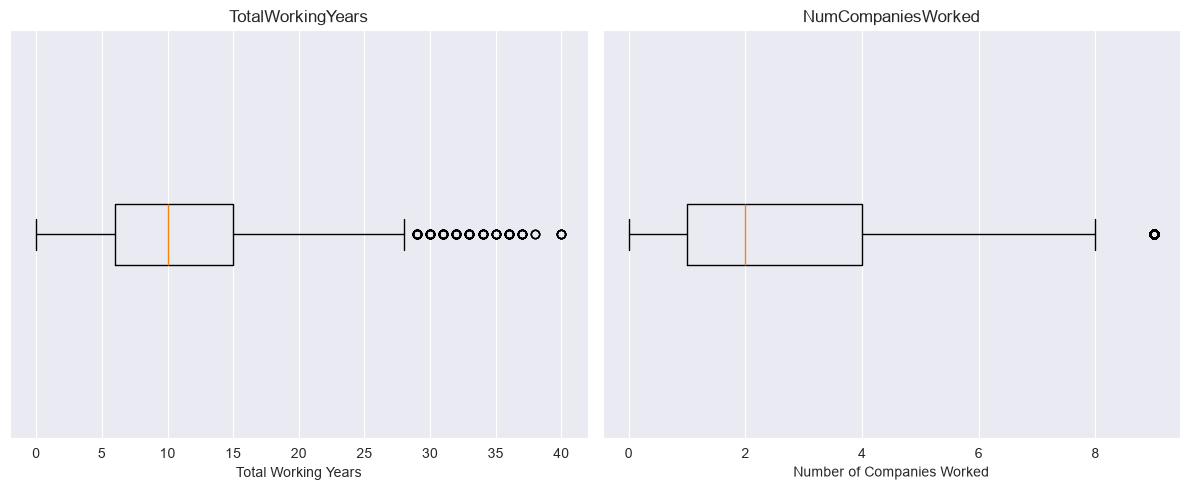

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    df['TotalWorkingYears'].dropna(),
    vert=False
)
axes[0].set_title('TotalWorkingYears')
axes[0].set_xlabel('Total Working Years')
axes[0].get_yaxis().set_visible(False)


axes[1].boxplot(
    df['NumCompaniesWorked'].dropna(),
    vert=False
)
axes[1].set_title('NumCompaniesWorked')
axes[1].set_xlabel('Number of Companies Worked')
axes[1].get_yaxis().set_visible(False)

plt.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

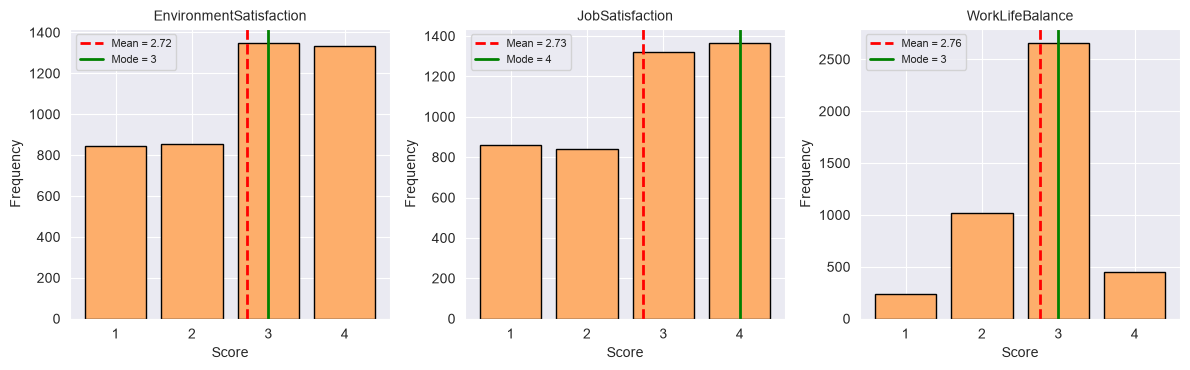

In [156]:
ORD_COLS = [
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'WorkLifeBalance'
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, col in zip(axes, ORD_COLS):

    data = df_employee[col].dropna()
    counts = data.value_counts().sort_index()

    ax.bar(
        counts.index.astype(int),
        counts.values,
        color="#fdae6b",
        edgecolor="black"
    )

    mean_value = data.mean()
    mode_value = data.mode().iloc[0]

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_value:.2f}"
    )

    ax.axvline(
        mode_value,
        color="green",
        linewidth=2,
        label=f"Mode = {int(mode_value)}"
    )

    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Score")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Handle missing values

In [157]:
for col in ["NumCompaniesWorked", "TotalWorkingYears"]:
    df[col] = df[col].fillna(df[col].median())

for col in ["EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]:
    df[col] = df[col].fillna(df[col].mode()[0])

int_cols = ["NumCompaniesWorked", "TotalWorkingYears",
            "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]
df[int_cols] = df[int_cols].astype(int)

df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0}).astype(int)

cat_cols = ["BusinessTravel", "Department", "EducationField",
            "Gender", "JobRole", "MaritalStatus"]
df[cat_cols] = df[cat_cols].astype("category")

# remove columns with constant features
const_cols = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=const_cols)


In [158]:
def prepare_time_df(df):
    df = df.rename(columns={'Unnamed: 0': 'EmployeeID'}).set_index('EmployeeID')
    return df.apply(pd.to_datetime, errors='coerce')

in_dt = prepare_time_df(df_inTime)
out_dt = prepare_time_df(df_outTime)
assert in_dt.shape == out_dt.shape and (in_dt.columns == out_dt.columns).all()

# holiday - no one in and out
holiday = in_dt.columns[in_dt.isna().all() & out_dt.isna().all()]
in_dt, out_dt = in_dt.drop(columns=holiday), out_dt.drop(columns=holiday)

# keep days with in and out
half = in_dt.isna() ^ out_dt.isna()
in_dt, out_dt = in_dt.mask(half), out_dt.mask(half)

# Valid duration: 0 < hours <= 24
hours = (out_dt - in_dt).apply(lambda s: s.dt.total_seconds() / 3600)
hours = hours.mask((hours <= 0) | (hours > 24))

# Aggregate per employee (absent days are skipped, not filled)
n_work = hours.shape[1]
att = pd.DataFrame({
    "AvgWorkHours": hours.mean(axis=1),
    "AbsentDays":   hours.isna().sum(axis=1),
})
att["AbsentRate"] = att["AbsentDays"] / n_work

# Employees with no valid day at all -> median
att["AvgWorkHours"] = att["AvgWorkHours"].fillna(att["AvgWorkHours"].median())
att = att.reset_index()

df_clean = df.merge(att, on="EmployeeID", how="left", validate="one_to_one")
df_clean = df_clean.reset_index(drop=True)

# Final check
assert df_clean.isnull().sum().sum() == 0
assert df_clean["EmployeeID"].is_unique

df_clean.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeID,Gender,JobLevel,...,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,AvgWorkHours,AbsentDays,AbsentRate
0,51,0,Travel_Rarely,Sales,6,2,Life Sciences,1,Female,1,...,0,0,3,4,2,3,3,7.373651,17,0.068273
1,31,1,Travel_Frequently,Research & Development,10,1,Life Sciences,2,Female,1,...,1,4,3,2,4,2,4,7.718969,13,0.052209
2,32,0,Travel_Frequently,Research & Development,17,4,Other,3,Male,4,...,0,3,2,2,1,3,3,7.013240,7,0.028112
3,38,0,Non-Travel,Research & Development,2,5,Life Sciences,4,Male,3,...,7,5,4,4,3,2,3,7.193678,14,0.056225
4,32,0,Travel_Rarely,Research & Development,10,1,Medical,5,Male,1,...,0,4,4,1,3,3,3,8.006175,4,0.016064
